### SUPPORT VECTOR MACHINE (SVM) CLASSIFICATION

importing libraries

In [9]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 

df = pd.read_csv("Heart_dataset")

display(df.head())
print("Dataset shape:", df.shape)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Dataset shape: (918, 12)


the dataset has 918 rows and 12 columns.

### seperate features and targets

In [3]:
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

categorical_columns = X.select_dtypes(include="object").columns
numeric_columns = X.select_dtypes(exclude="object").columns

print("Categorical features:", list(categorical_columns))
print("Numeric features:", list(numeric_columns))

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Numeric features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


C:\Users\Nandini\AppData\Local\Temp\ipykernel_9220\735407795.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


### train test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 734
Test rows: 184


### Prepare features and create the SVM model

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_columns),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("svm", SVC(kernel="rbf"))
])

model.fit(X_train, y_train);

- StandardScaler puts numeric features on comparable scales.
- OneHotEncoder converts text categories, such as ChestPainType, into numeric columns.
- Pipeline applies these preparation steps before training the SVM.
- SVC(kernel="rbf") creates an SVM classifier with an RBF kernel, which can learn curved decision boundaries.
- fit() trains the full pipeline using the training data.

### Predict and evaluate

Accuracy: 0.897

Confusion matrix:
[[70 12]
 [ 7 95]]

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.91      0.85      0.88        82
   Heart disease       0.89      0.93      0.91       102

        accuracy                           0.90       184
       macro avg       0.90      0.89      0.89       184
    weighted avg       0.90      0.90      0.90       184



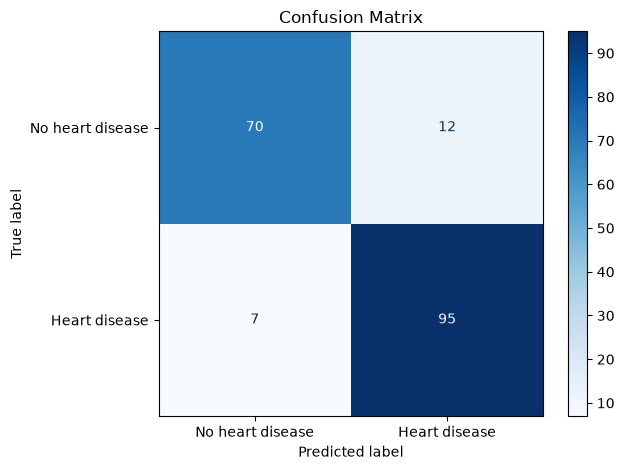

In [12]:
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["No heart disease", "Heart disease"]
))
ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, predictions),
        display_labels=["No heart disease", "Heart disease"],
    ).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix")
plt.tight_layout()
plt.show()
